# Embedding

In [ ]:
import torch
import spacy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from torch.nn import functional as F

plt.style.use("ggplot")

In [ ]:
text = "the kid is in the park with the kid"
vocab = list(set(text.split()))
vocab

['in', 'with', 'is', 'kid', 'park', 'the']

In [ ]:
text2int = pd.Series(range(len(vocab)), index=vocab)
text2int

,0
in,0
with,1
is,2
kid,3
park,4
the,5


In [ ]:
embedding = torch.nn.Embedding(num_embeddings=len(vocab), embedding_dim=2)

In [ ]:
embedding.weight

Parameter containing:
tensor([[ 0.2064, -0.5106],
        [ 1.0626, -1.0100],
        [ 0.1852, -0.7351],
        [ 0.4590,  0.1672],
        [ 0.8845,  1.4895],
        [ 1.9914, -0.5257]], requires_grad=True)

In [ ]:
x_int = text2int[text.split()].values.reshape(1, -1)
x_int

array([[5, 3, 2, 0, 5, 4, 1, 5, 3]])

In [ ]:
embedding(torch.tensor(x_int))

tensor([[[ 1.9914, -0.5257],
         [ 0.4590,  0.1672],
         [ 0.1852, -0.7351],
         [ 0.2064, -0.5106],
         [ 1.9914, -0.5257],
         [ 0.8845,  1.4895],
         [ 1.0626, -1.0100],
         [ 1.9914, -0.5257],
         [ 0.4590,  0.1672]]], grad_fn=<EmbeddingBackward0>)

In [ ]:
text1 = "my pet is a cat"
text2 = "my pet is a dog"
text3 = "the gear is part of the engine"

In [ ]:
nlp = spacy.load("en_core_web_sm")

In [ ]:
doc1 = nlp(text1)
doc2 = nlp(text2)
doc3 = nlp(text3)

In [ ]:
vec1 = list(doc1)[-1].vector
vec2 = list(doc2)[-1].vector
vec3 = list(doc3)[-1].vector

In [ ]:
vec1 @ vec2 / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

np.float32(0.8468464)

In [ ]:
vec1 @ vec3 / (np.linalg.norm(vec1) * np.linalg.norm(vec3))

np.float32(0.5198557)

In [ ]:
vec2 @ vec3 / (np.linalg.norm(vec2) * np.linalg.norm(vec3))

np.float32(0.5743724)

# Positional Encoding

* $N$: Numero de documentos.
* $C$: Tamano de contexto.
* $L$: Dimension de embedding.

1. Sequencias iniciales: $(N, C)$
2. Embeddings: $(N, C, L)$

In [ ]:
class PositionalEncoding(torch.nn.Module):
    encoding: torch.Tensor

    def __init__(self, embedding_dim: int, context_size: int):
        super().__init__()

        position = torch.arange(context_size).double().reshape(-1, 1)
        _2i = torch.arange(0, embedding_dim, 2).double()
        encoding = torch.zeros(size=(1, context_size, embedding_dim))

        encoding[0, :, ::2] = torch.sin(position / (10000 ** (_2i / embedding_dim)))
        encoding[0, :, 1::2] = torch.cos(position / (10000 ** (_2i / embedding_dim)))
        self.register_buffer("encoding", encoding)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # (N, K, L)
        return x + self.encoding

In [ ]:
pe = PositionalEncoding(embedding_dim=50, context_size=100)

In [ ]:
pe_matrix = pe.encoding.detach().clone().numpy()

In [ ]:
pe_matrix

array([[[ 0.0000000e+00,  1.0000000e+00,  0.0000000e+00, ...,
          1.0000000e+00,  0.0000000e+00,  1.0000000e+00],
        [ 8.4147096e-01,  5.4030228e-01,  6.3794822e-01, ...,
          1.0000000e+00,  1.4454397e-04,  1.0000000e+00],
        [ 9.0929741e-01, -4.1614684e-01,  9.8254138e-01, ...,
          9.9999994e-01,  2.8908794e-04,  9.9999994e-01],
        ...,
        [ 3.7960774e-01, -9.2514753e-01, -9.0617859e-01, ...,
          9.9979466e-01,  1.4020306e-02,  9.9990171e-01],
        [-5.7338190e-01, -8.1928825e-01, -9.6761459e-01, ...,
          9.9979037e-01,  1.4164836e-02,  9.9989969e-01],
        [-9.9920684e-01,  3.9820880e-02, -5.8410120e-01, ...,
          9.9978608e-01,  1.4309365e-02,  9.9989760e-01]]],
      shape=(1, 100, 50), dtype=float32)

In [ ]:
list(map(int, bin(5)[2:]))

[1, 0, 1]

In [ ]:
def generate_bins(embedding_dim: int, context_dim: int) -> np.typing.NDArray:
    encoding = np.zeros(shape=(context_dim, embedding_dim))
    for i in range(context_dim):
        vals = list(map(int, bin(i)[2:]))
        encoding[i, :len(vals)] = vals[::-1]
    return encoding

In [ ]:
bin_encoding = generate_bins(50, 100)

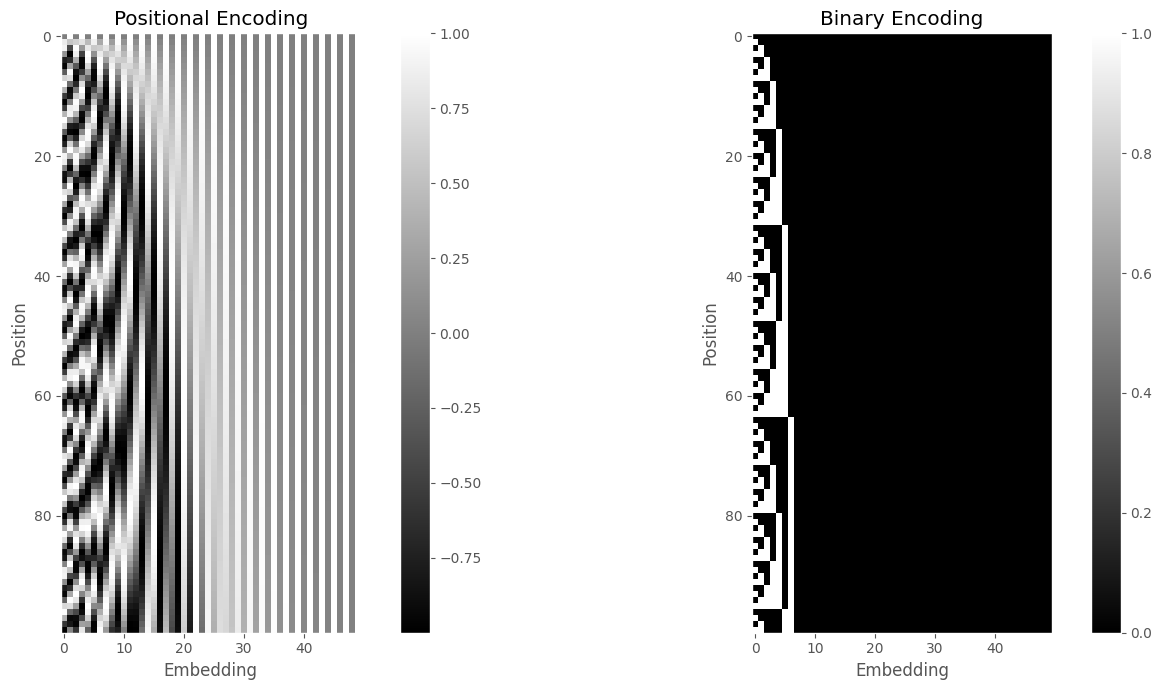

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
ax = axes[0]
im = ax.imshow(pe_matrix[0], cmap="gray")
fig.colorbar(im, ax=ax)
ax.set(xlabel="Embedding", ylabel="Position", title="Positional Encoding")
ax.grid(False)

ax = axes[1]
im = ax.imshow(bin_encoding, cmap="gray")
fig.colorbar(im, ax=ax)
ax.set(xlabel="Embedding", ylabel="Position", title="Binary Encoding")
ax.grid(False)

fig.tight_layout()

# Attention

\begin{equation}
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q \cdot K^T}{\sqrt{d_k}}\right) \cdot V\\
Q = X \cdot W_q + b\\
K = X \cdot W_k + b\\
V = X \cdot W_v + b\\
\text{softmax}(\vec{x}) = \left[\frac{e^x_1}{\sum_i{e^x_i}}, \frac{e^x_2}{\sum_i{e^x_i}}, \dots, \frac{e^x_N}{\sum_i{e^x_i}}\right]
\end{equation}

In [ ]:
class ScaledDotProductAttention(torch.nn.Module):
    def __init__(self, embedding_dim: int):
        super().__init__()
        self.query_layer = torch.nn.Linear(embedding_dim, embedding_dim)
        self.key_layer = torch.nn.Linear(embedding_dim, embedding_dim)
        self.value_layer = torch.nn.Linear(embedding_dim, embedding_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        q = self.query_layer(x)
        k = self.key_layer(x)
        v = self.value_layer(x)

        attention_matrix = F.softmax(q @ k.transpose(1, 2) / np.sqrt(x.shape[2]), dim=-1)
        return attention_matrix @ v

In [ ]:
x = torch.randn(size=(2, 50, 100))
attention = ScaledDotProductAttention(embedding_dim=100)
y = attention(x)
print(y.shape)

torch.Size([2, 50, 100])


In [ ]:
x.transpose(1, 2).shape

torch.Size([2, 100, 50])

In [ ]:
def softmax(x: torch.Tensor) -> torch.Tensor:
    exps = torch.exp(x)
    return exps / torch.sum(exps)

In [ ]:
x = torch.randn(size=(10, ))
s = softmax(x / 0.1)

In [ ]:
x

tensor([ 0.7151,  0.1744,  0.2098, -1.3977, -1.6260,  1.0864, -0.4594, -1.2800,
         0.5613, -2.4986])

In [ ]:
s

tensor([2.3708e-02, 1.0630e-04, 1.5145e-04, 1.5805e-11, 1.6133e-12, 9.7094e-01,
        1.8791e-07, 5.1320e-11, 5.0911e-03, 2.6169e-16])

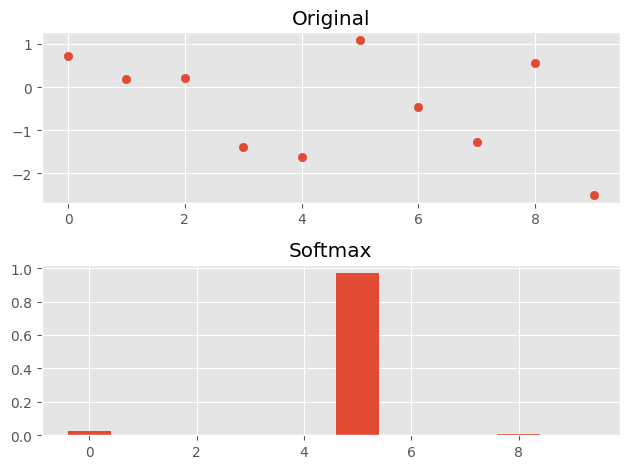

In [ ]:
fig, axes = plt.subplots(2, 1)
ax = axes[0]
ax.scatter(range(len(x)), x)
ax.set(title="Original")
ax = axes[1]
ax.bar(range(len(s)), s)
ax.set(title="Softmax")
fig.tight_layout()

In [ ]:
s.sum()

tensor(1.0000)

In [ ]:
class MultiHeadAttention(torch.nn.Module):
    def __init__(self, embedding_dim: int, num_heads: int):
        super().__init__()
        self.layers = torch.nn.ModuleList(
            [ScaledDotProductAttention(embedding_dim=embedding_dim) for _ in range(num_heads)]
        )
        self.projection_layer = torch.nn.Linear(num_heads * embedding_dim, embedding_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        outputs = torch.concat([layer(x) for layer in self.layers], dim=-1)
        return self.projection_layer(outputs)

In [ ]:
attention = MultiHeadAttention(embedding_dim=100, num_heads=5)
x = torch.randn(size=(2, 50, 100))
y = attention(x)
print(y.shape)

torch.Size([2, 50, 100])


In [ ]:
layer = torch.nn.MultiheadAttention(embed_dim=100, num_heads=5, batch_first=True)
x = torch.randn(size=(2, 50, 100))
y, attention_mask = layer(x, x, x)
print(y.shape)
print(attention_mask.shape)

torch.Size([2, 50, 100])
torch.Size([2, 50, 50])


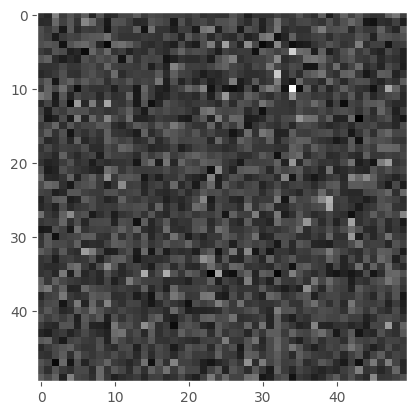

In [ ]:
fig, ax = plt.subplots()
ax.imshow(attention_mask[0].detach().numpy(), cmap="gray")
ax.grid(False)